In [1]:

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.inspection import permutation_importance

from sklearn.dummy import DummyRegressor

In [2]:


PROJECT_ROOT = Path.cwd()

# Permet aussi de fonctionner si le notebook est lancé depuis notebooks/
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "banana_shelf_life_synthetic.csv"
)

df = pd.read_csv(DATA_PATH)

print(f"Dataset chargé : {DATA_PATH}")
print(f"Dimensions : {df.shape[0]} lignes × {df.shape[1]} colonnes")

display(df.head())


Dataset chargé : c:\Users\babacar\model_ml_iot\data\processed\banana_shelf_life_synthetic.csv
Dimensions : 8641 lignes × 12 colonnes


,lot_id,storage_day,temperature,humidity,mq2_raw,fc28_raw,liquid_detected,motion_detected,ldr_raw,quality,days_until_bad,is_expired
0,LOT-0001,0,13.43,87.37,619,3223,0,0,2148,acceptable,29,0
1,LOT-0001,1,12.17,94.45,857,3176,0,0,761,acceptable,28,0
2,LOT-0001,2,13.10,90.10,846,2957,0,0,1296,acceptable,27,0
3,LOT-0001,3,12.64,90.55,962,3067,0,0,2574,acceptable,26,0
4,LOT-0001,4,12.52,93.58,906,3134,0,0,3622,acceptable,25,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8641 entries, 0 to 8640
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   lot_id           8641 non-null   str    
 1   storage_day      8641 non-null   int64  
 2   temperature      8641 non-null   float64
 3   humidity         8641 non-null   float64
 4   mq2_raw          8641 non-null   int64  
 5   fc28_raw         8641 non-null   int64  
 6   liquid_detected  8641 non-null   int64  
 7   motion_detected  8641 non-null   int64  
 8   ldr_raw          8641 non-null   int64  
 9   quality          8641 non-null   str    
 10  days_until_bad   8641 non-null   int64  
 11  is_expired       8641 non-null   int64  
dtypes: float64(2), int64(8), str(2)
memory usage: 961.2 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
storage_day,8641.0,14.349265,9.048442,0.00,7.00,14.00,21.00,40.00
temperature,8641.0,13.577530,1.072548,9.48,12.84,13.59,14.32,17.78
humidity,8641.0,89.960974,3.814918,75.14,87.41,90.01,92.62,103.03
mq2_raw,8641.0,1183.005092,290.084230,409.00,955.00,1171.00,1399.00,2120.00
fc28_raw,8641.0,2698.910658,364.484130,1345.00,2441.00,2711.00,2970.00,3764.00
liquid_detected,8641.0,0.004513,0.067034,0.00,0.00,0.00,0.00,1.00
motion_detected,8641.0,0.354473,0.478381,0.00,0.00,0.00,1.00,1.00
ldr_raw,8641.0,2114.435251,1031.183839,302.00,1225.00,2130.00,3011.00,3900.00
days_until_bad,8641.0,14.349265,9.048442,0.00,7.00,14.00,21.00,40.00
is_expired,8641.0,0.034718,0.183076,0.00,0.00,0.00,0.00,1.00


In [5]:
df.isna().sum()

lot_id             0
storage_day        0
temperature        0
humidity           0
mq2_raw            0
fc28_raw           0
liquid_detected    0
motion_detected    0
ldr_raw            0
quality            0
days_until_bad     0
is_expired         0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df['storage_day'].min(), df['storage_day'].max()

(np.int64(0), np.int64(40))

distribution de la cible

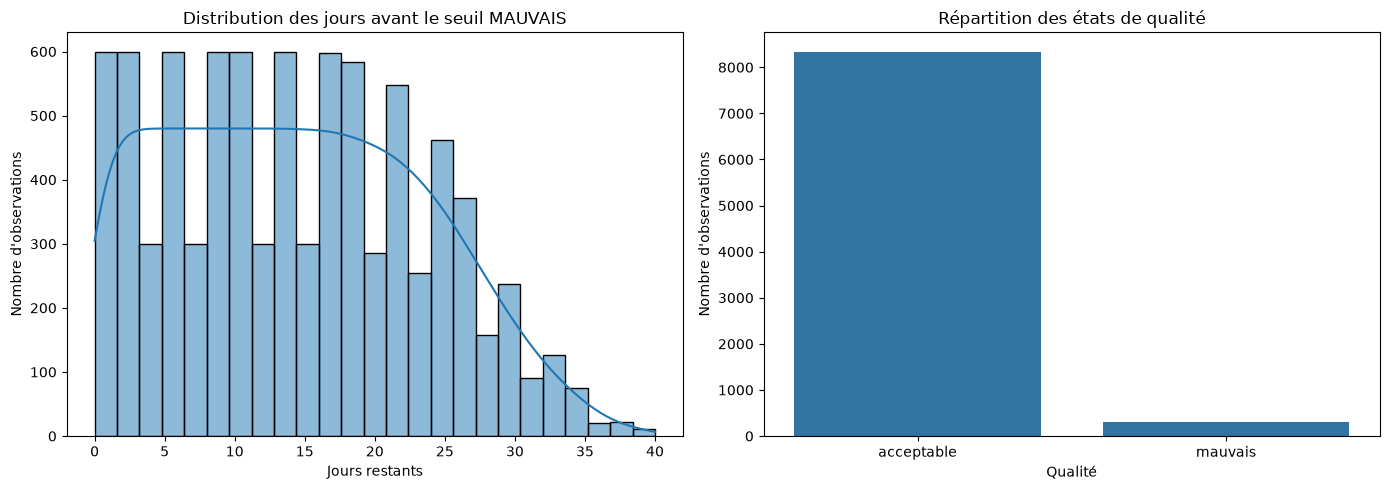

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="days_until_bad",
    bins=25,
    kde=True,
    ax=axes[0],
)
axes[0].set_title("Distribution des jours avant le seuil MAUVAIS")
axes[0].set_xlabel("Jours restants")
axes[0].set_ylabel("Nombre d'observations")

sns.countplot(
    data=df,
    x="quality",
    order=["acceptable", "mauvais"],
    ax=axes[1],
)
axes[1].set_title("Répartition des états de qualité")
axes[1].set_xlabel("Qualité")
axes[1].set_ylabel("Nombre d'observations")

plt.tight_layout()
plt.show()


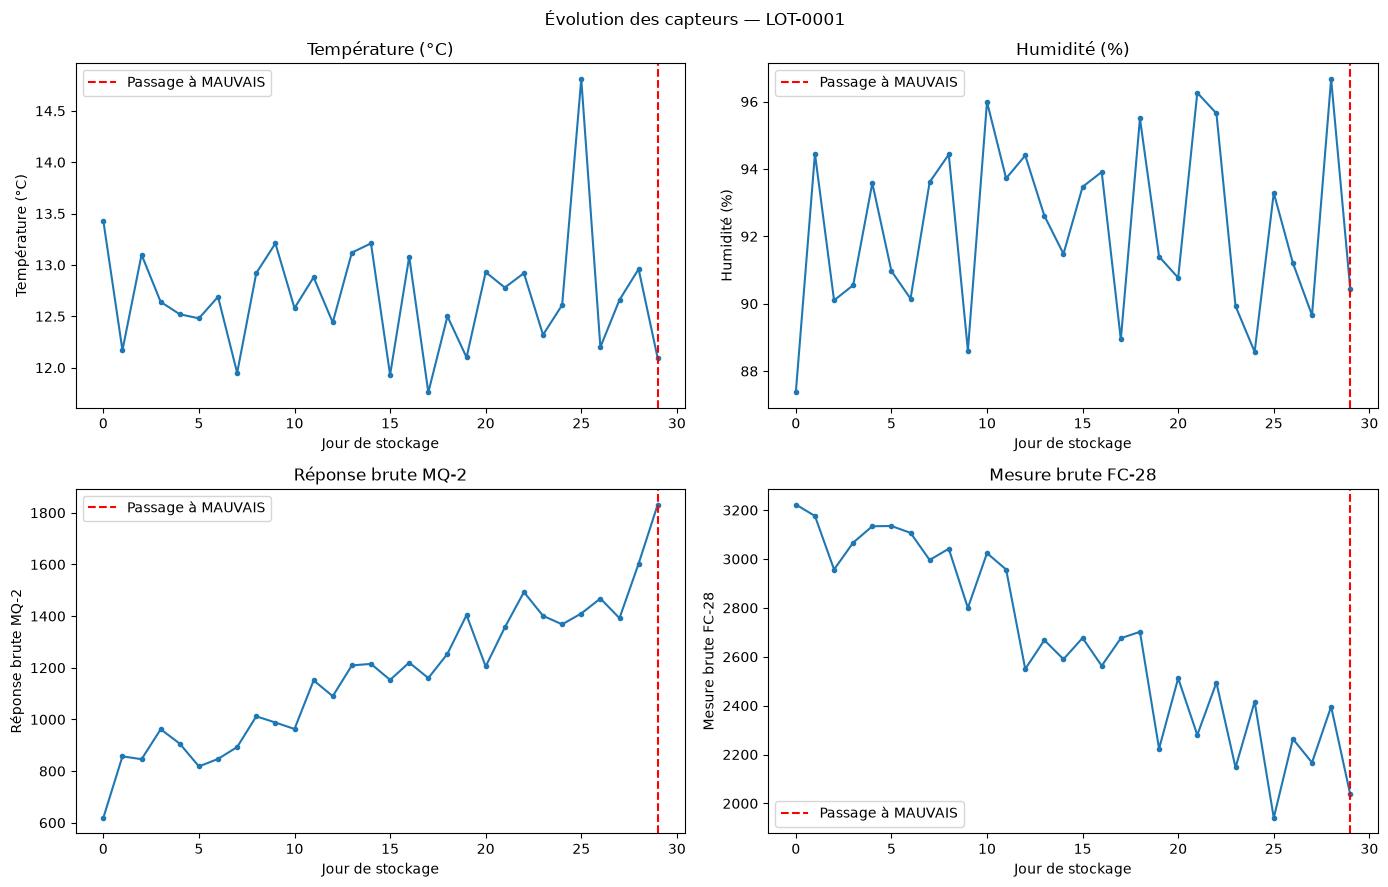

In [9]:

lot_example = df["lot_id"].iloc[0]
lot_df = (
    df[df["lot_id"] == lot_example]
    .sort_values("storage_day")
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sensor_plots = [
    ("temperature", "Température (°C)"),
    ("humidity", "Humidité (%)"),
    ("mq2_raw", "Réponse brute MQ-2"),
    ("fc28_raw", "Mesure brute FC-28"),
]

for ax, (column, label) in zip(axes.flat, sensor_plots):
    ax.plot(lot_df["storage_day"], lot_df[column], marker="o", markersize=3)
    ax.axvline(
        lot_df.loc[lot_df["quality"].eq("mauvais"), "storage_day"].min(),
        color="red",
        linestyle="--",
        label="Passage à MAUVAIS",
    )
    ax.set_title(label)
    ax.set_xlabel("Jour de stockage")
    ax.set_ylabel(label)
    ax.legend()

plt.suptitle(f"Évolution des capteurs — {lot_example}")
plt.tight_layout()
plt.show()


mesure les relations entre les capteurs, le temps de stockage et notre cible days_until_bad.

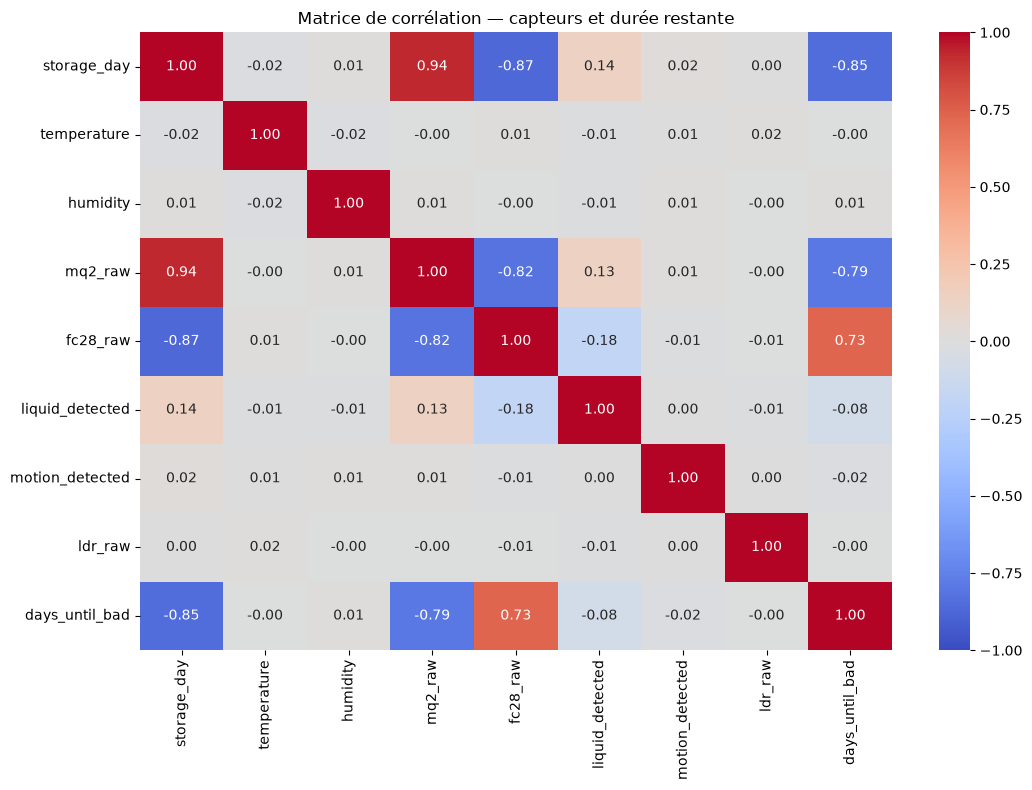

Corrélations avec days_until_bad :


,correlation
storage_day,-0.845210
mq2_raw,-0.794387
liquid_detected,-0.082934
motion_detected,-0.018926
temperature,-0.002460
ldr_raw,-0.002255
humidity,0.009006
fc28_raw,0.730347


In [10]:

# Variables numériques pertinentes pour l'analyse
analysis_columns = [
    "storage_day",
    "temperature",
    "humidity",
    "mq2_raw",
    "fc28_raw",
    "liquid_detected",
    "motion_detected",
    "ldr_raw",
    "days_until_bad",
]

corr = df[analysis_columns].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Matrice de corrélation — capteurs et durée restante")
plt.tight_layout()
plt.show()

# Corrélations avec la cible
target_corr = (
    corr["days_until_bad"]
    .drop("days_until_bad")
    .sort_values()
)

print("Corrélations avec days_until_bad :")
display(target_corr.to_frame("correlation"))


In [11]:
# Vérification de la cohérence des trajectoires
lot_summary = (
    df.groupby("lot_id")
    .agg(
        first_day=("storage_day", "min"),
        last_day=("storage_day", "max"),
        bad_observations=("is_expired", "sum"),
        minimum_remaining=("days_until_bad", "min"),
    )
)

print("Nombre de lots :", len(lot_summary))
print("\nLots sans observation MAUVAIS :",
      (lot_summary["bad_observations"] == 0).sum())

print("\nLots avec plusieurs observations MAUVAIS :",
      (lot_summary["bad_observations"] > 1).sum())

print("\nStatistiques du jour de transition :")
display(lot_summary["last_day"].describe())

# Séparation par lot : aucun lot partagé entre train et test
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42,
)

train_idx, test_idx = next(
    splitter.split(df, groups=df["lot_id"])
)

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

print("\nLots entraînement :", train_df["lot_id"].nunique())
print("Lots test :", test_df["lot_id"].nunique())
print(
    "Intersection des lots :",
    set(train_df["lot_id"]) & set(test_df["lot_id"]),
)


Nombre de lots : 300

Lots sans observation MAUVAIS : 0

Lots avec plusieurs observations MAUVAIS : 0

Statistiques du jour de transition :


count    300.000000
mean      27.803333
std        5.086344
min       14.000000
25%       24.750000
50%       28.000000
75%       31.000000
max       40.000000
Name: last_day, dtype: float64


Lots entraînement : 240
Lots test : 60
Intersection des lots : set()


In [12]:
# Jour où chaque lot passe à MAUVAIS
expiration_by_lot = (
    df.groupby("lot_id")
    .agg(
        expiration_day=("storage_day", "max"),
        mean_temperature=("temperature", "mean"),
        mean_humidity=("humidity", "mean"),
        mean_mq2=("mq2_raw", "mean"),
        mean_fc28=("fc28_raw", "mean"),
    )
    .reset_index()
)

sensor_columns = {
    "mean_temperature": "Température moyenne",
    "mean_humidity": "Humidité moyenne",
    "mean_mq2": "MQ-2 moyen",
    "mean_fc28": "FC-28 moyen",
}

correlations = expiration_by_lot[
    ["expiration_day", *sensor_columns.keys()]
].corr()["expiration_day"].drop("expiration_day")

correlations.index = [
    sensor_columns[column] for column in correlations.index
]

display(correlations.sort_values(ascending=False).to_frame("Corrélation avec le jour d'expiration"))

,Corrélation avec le jour d'expiration
MQ-2 moyen,0.963387
Humidité moyenne,0.027767
Température moyenne,-0.036261
FC-28 moyen,-0.938061


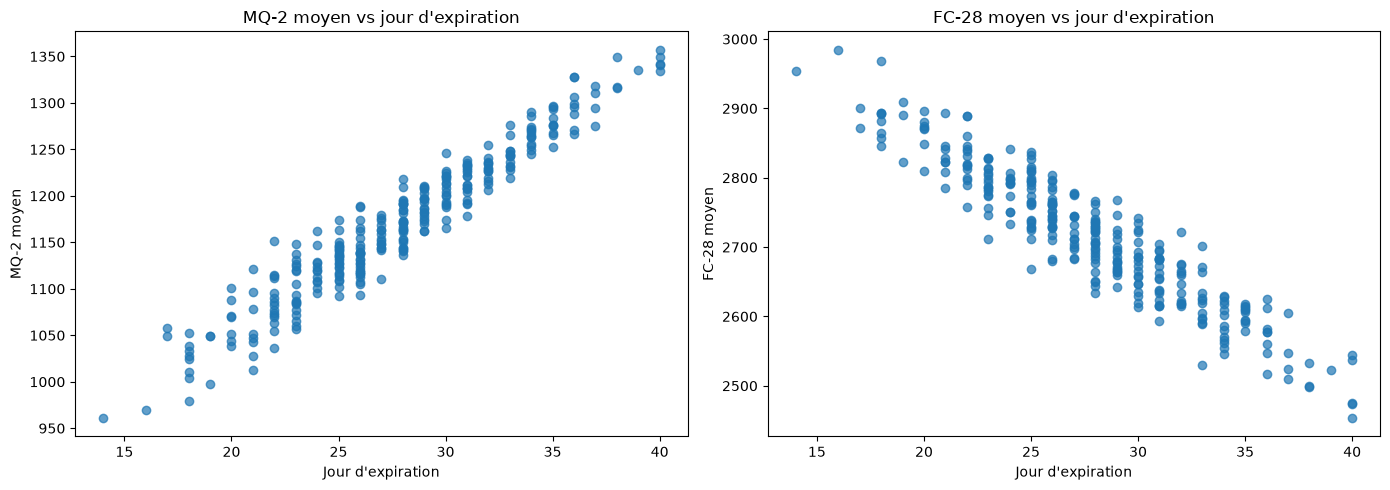

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    expiration_by_lot["expiration_day"],
    expiration_by_lot["mean_mq2"],
    alpha=0.7,
)
axes[0].set_title("MQ-2 moyen vs jour d'expiration")
axes[0].set_xlabel("Jour d'expiration")
axes[0].set_ylabel("MQ-2 moyen")

axes[1].scatter(
    expiration_by_lot["expiration_day"],
    expiration_by_lot["mean_fc28"],
    alpha=0.7,
)
axes[1].set_title("FC-28 moyen vs jour d'expiration")
axes[1].set_xlabel("Jour d'expiration")
axes[1].set_ylabel("FC-28 moyen")

plt.tight_layout()
plt.show()

Construction le premier modèle de régression

In [14]:
# Variables disponibles et cible à prédire
print("Colonnes du dataset :")
print(df.columns.tolist())

print("\nExemple de données :")
display(
    df[
        [
            "lot_id",
            "storage_day",
            "temperature",
            "humidity",
            "mq2_raw",
            "fc28_raw",
            "days_until_bad",
            "is_expired",
            "quality",
        ]
    ].head(10)
)

print("\nDistribution de la cible :")
display(df["days_until_bad"].describe())

Colonnes du dataset :
['lot_id', 'storage_day', 'temperature', 'humidity', 'mq2_raw', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw', 'quality', 'days_until_bad', 'is_expired']

Exemple de données :


,lot_id,storage_day,temperature,humidity,mq2_raw,fc28_raw,days_until_bad,is_expired,quality
0,LOT-0001,0,13.43,87.37,619,3223,29,0,acceptable
1,LOT-0001,1,12.17,94.45,857,3176,28,0,acceptable
2,LOT-0001,2,13.10,90.10,846,2957,27,0,acceptable
3,LOT-0001,3,12.64,90.55,962,3067,26,0,acceptable
4,LOT-0001,4,12.52,93.58,906,3134,25,0,acceptable
5,LOT-0001,5,12.48,90.97,818,3135,24,0,acceptable
6,LOT-0001,6,12.69,90.15,847,3107,23,0,acceptable
7,LOT-0001,7,11.95,93.61,893,2996,22,0,acceptable
8,LOT-0001,8,12.92,94.43,1012,3042,21,0,acceptable
9,LOT-0001,9,13.21,88.61,988,2800,20,0,acceptable



Distribution de la cible :


count    8641.000000
mean       14.349265
std         9.048442
min         0.000000
25%         7.000000
50%        14.000000
75%        21.000000
max        40.000000
Name: days_until_bad, dtype: float64

In [15]:
# Cible : nombre de jours restants avant le passage à MAUVAIS
TARGET = "days_until_bad"

# Modèle A : mesures des capteurs uniquement
sensor_features = [
    "temperature",
    "humidity",
    "mq2_raw",
    "fc28_raw",
    "liquid_detected",
    "motion_detected",
    "ldr_raw",
]

# Modèle B : mesures des capteurs + jour de stockage
sensor_day_features = sensor_features + ["storage_day"]

# Séparation commune aux deux modèles, par lot
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42,
)

train_idx, test_idx = next(
    splitter.split(df, groups=df["lot_id"])
)

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

# Données du modèle A
X_train_A = train_df[sensor_features]
X_test_A = test_df[sensor_features]

# Données du modèle B
X_train_B = train_df[sensor_day_features]
X_test_B = test_df[sensor_day_features]

# Cible commune
y_train = train_df[TARGET]
y_test = test_df[TARGET]

print("Observations d'entraînement :", len(train_df))
print("Observations de test :", len(test_df))
print("Lots d'entraînement :", train_df["lot_id"].nunique())
print("Lots de test :", test_df["lot_id"].nunique())
print(
    "Lots partagés :",
    len(set(train_df["lot_id"]) & set(test_df["lot_id"]))
)
print("Variables du modèle A :", X_train_A.columns.tolist())
print("Variables du modèle B :", X_train_B.columns.tolist())


Observations d'entraînement : 6916
Observations de test : 1725
Lots d'entraînement : 240
Lots de test : 60
Lots partagés : 0
Variables du modèle A : ['temperature', 'humidity', 'mq2_raw', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw']
Variables du modèle B : ['temperature', 'humidity', 'mq2_raw', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw', 'storage_day']


Entraîner et comparer les modèles

In [16]:
# Modèles à comparer
models = {
    "Régression linéaire": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    ),
}

feature_sets = {
    "A - Capteurs seuls": (X_train_A, X_test_A),
    "B - Capteurs + jour": (X_train_B, X_test_B),
}

results = []
trained_models = {}

for feature_name, (X_train, X_test) in feature_sets.items():
    for model_name, model in models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        mae = mean_absolute_error(y_test, predictions)
        rmse = mean_squared_error(y_test, predictions) ** 0.5
        r2 = r2_score(y_test, predictions)

        results.append({
            "Variables": feature_name,
            "Modèle": model_name,
            "MAE (jours)": round(mae, 3),
            "RMSE (jours)": round(rmse, 3),
            "R²": round(r2, 3),
        })

        trained_models[(feature_name, model_name)] = model

results_df = pd.DataFrame(results).sort_values("MAE (jours)")
display(results_df)


,Variables,Modèle,MAE (jours),RMSE (jours),R²
3,B - Capteurs + jour,Random Forest,3.597,4.539,0.742
2,B - Capteurs + jour,Régression linéaire,3.619,4.542,0.742
0,A - Capteurs seuls,Régression linéaire,4.024,5.081,0.677
1,A - Capteurs seuls,Random Forest,4.111,5.196,0.663


Nous avons nos premiers résultats de modélisation. Le modèle le plus performant est la Random Forest avec les capteurs et le jour de stockage, avec une MAE de 3,597 jours et un \(R^2\) de 0,742.
1. Comparaison des résultats
Modèle	MAE (jours)	RMSE (jours)	R²
Random Forest + jour	3,597	4,539	0,742
Régression linéaire + jour	3,619	4,542	0,742
Régression linéaire, capteurs seuls	4,024	5,081	0,677
Random Forest, capteurs seuls	4,111	5,196	0,663
Ce qu'on peut conclure
- L'ajout de storage_day améliore les résultats pour les deux algorithmes.
- La Random Forest ne dépasse la régression linéaire que de très peu lorsque le jour de stockage est inclus.
- Avec une MAE de 3,597 jours, le modèle se trompe en moyenne d'environ 3,6 jours sur les observations de test.

Analyser les erreurs du meilleur modèle

In [17]:

# Récupérer le meilleur modèle
best_model = trained_models[
    ("B - Capteurs + jour", "Random Forest")
]

predictions = best_model.predict(X_test_B)

evaluation_df = test_df[
    ["lot_id", "storage_day", "days_until_bad", "quality"]
].copy()

evaluation_df["predicted_days_until_bad"] = predictions
evaluation_df["absolute_error"] = (
    evaluation_df["days_until_bad"]
    - evaluation_df["predicted_days_until_bad"]
).abs()

# Afficher quelques prédictions
display(
    evaluation_df[
        [
            "lot_id",
            "storage_day",
            "days_until_bad",
            "predicted_days_until_bad",
            "absolute_error",
        ]
    ].head(15).round(2)
)

print("\nErreur moyenne par tranche de durée restante :")

evaluation_df["remaining_days_group"] = pd.cut(
    evaluation_df["days_until_bad"],
    bins=[-1, 3, 7, 14, 21, 40],
    labels=["0–3 jours", "4–7 jours", "8–14 jours",
            "15–21 jours", "22 jours et plus"],
)

display(
    evaluation_df.groupby(
        "remaining_days_group",
        observed=False,
    )["absolute_error"]
    .agg(["count", "mean", "median"])
    .round(2)
)


,lot_id,storage_day,days_until_bad,predicted_days_until_bad,absolute_error
141,LOT-0006,0,29,28.38,0.62
142,LOT-0006,1,28,28.10,0.10
143,LOT-0006,2,27,25.21,1.79
144,LOT-0006,3,26,23.09,2.91
145,LOT-0006,4,25,25.61,0.61
146,LOT-0006,5,24,23.35,0.65
147,LOT-0006,6,23,20.79,2.21
148,LOT-0006,7,22,23.00,1.00
149,LOT-0006,8,21,20.07,0.93
150,LOT-0006,9,20,17.14,2.86



Erreur moyenne par tranche de durée restante :


,count,mean,median
remaining_days_group,,,
0–3 jours,240,3.67,3.26
4–7 jours,240,3.05,2.36
8–14 jours,420,3.42,2.84
15–21 jours,410,3.69,2.88
22 jours et plus,415,3.96,3.13


visualiser les prédictions

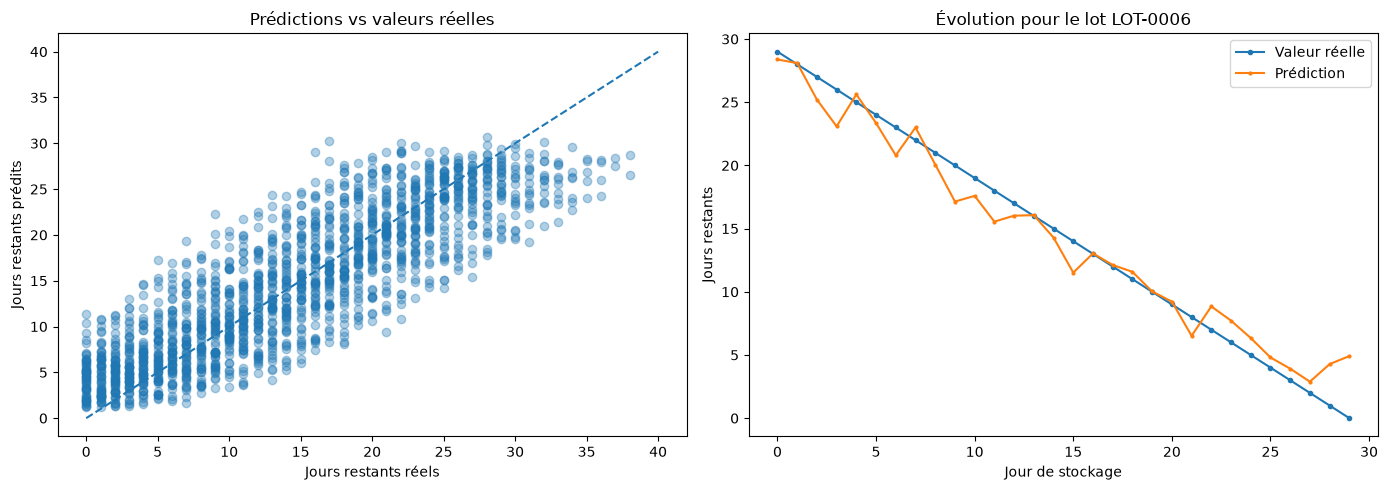

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : valeurs réelles vs prédictions
axes[0].scatter(
    evaluation_df["days_until_bad"],
    evaluation_df["predicted_days_until_bad"],
    alpha=0.35,
)

axes[0].plot(
    [0, 40],
    [0, 40],
    linestyle="--",
)

axes[0].set_xlabel("Jours restants réels")
axes[0].set_ylabel("Jours restants prédits")
axes[0].set_title("Prédictions vs valeurs réelles")

# Graphique 2 : évolution pour un seul lot
example_lot = evaluation_df["lot_id"].iloc[0]

lot_results = (
    evaluation_df[evaluation_df["lot_id"] == example_lot]
    .sort_values("storage_day")
)

axes[1].plot(
    lot_results["storage_day"],
    lot_results["days_until_bad"],
    marker="o",
    markersize=3,
    label="Valeur réelle",
)

axes[1].plot(
    lot_results["storage_day"],
    lot_results["predicted_days_until_bad"],
    marker=".",
    markersize=4,
    label="Prédiction",
)

axes[1].set_xlabel("Jour de stockage")
axes[1].set_ylabel("Jours restants")
axes[1].set_title(f"Évolution pour le lot {example_lot}")
axes[1].legend()

plt.tight_layout()
plt.show()


In [19]:

# Référence : prédire la moyenne de la cible d'entraînement
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_B, y_train)

baseline_predictions = baseline.predict(X_test_B)

# Prédictions du meilleur modèle actuel
rf_model = trained_models[
    ("B - Capteurs + jour", "Random Forest")
]
rf_predictions = rf_model.predict(X_test_B)

comparison = pd.DataFrame([
    {
        "Modèle": "Référence naïve (moyenne)",
        "MAE (jours)": mean_absolute_error(y_test, baseline_predictions),
        "RMSE (jours)": mean_squared_error(
            y_test, baseline_predictions
        ) ** 0.5,
        "R²": r2_score(y_test, baseline_predictions),
    },
    {
        "Modèle": "Random Forest",
        "MAE (jours)": mean_absolute_error(y_test, rf_predictions),
        "RMSE (jours)": mean_squared_error(
            y_test, rf_predictions
        ) ** 0.5,
        "R²": r2_score(y_test, rf_predictions),
    },
])

display(comparison.round(3))


,Modèle,MAE (jours),RMSE (jours),R²
0,Référence naïve (moyenne),7.592,8.945,-0.000
1,Random Forest,3.597,4.539,0.742


Cette comparaison confirme que la Random Forest apprend des relations utiles dans notre dataset synthétique, au lieu de simplement prédire une valeur moyenne.
1. Résultat de la comparaison
Random Forest — modèle actuel
3,597 jours
Erreur absolue moyenne (MAE)

Référence naïve
7,592 jours

Réduction de la MAE
52,6 %


La Random Forest réduit l'erreur absolue moyenne d'environ 52,6 % par rapport à la référence naïve. Son \(R^2=0{,}742\) indique également qu'elle explique une part importante de la variabilité observée sur le jeu de test.
Cela valide le fonctionnement initial de notre pipeline de régression.

,Variable,Importance
7,storage_day,0.7541
1,humidity,0.0508
0,temperature,0.0489
3,fc28_raw,0.0473
6,ldr_raw,0.0469
2,mq2_raw,0.0463
5,motion_detected,0.0056
4,liquid_detected,0.0000


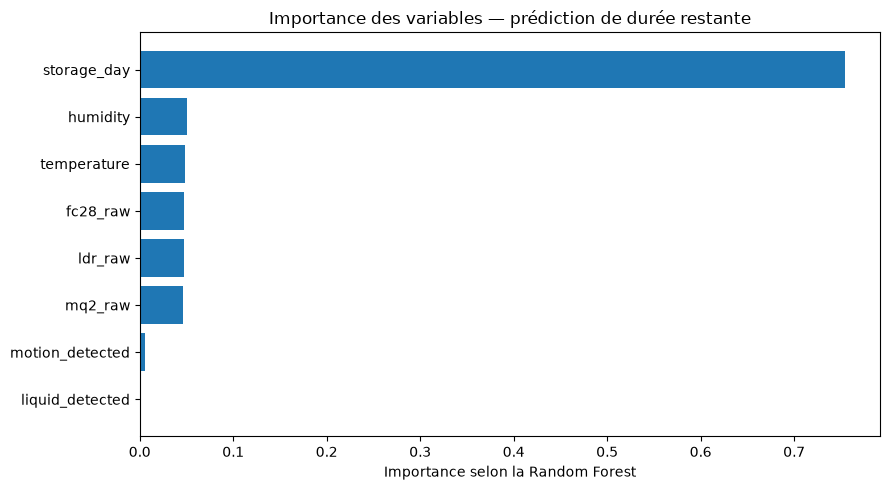

In [20]:

rf_model = trained_models[
    ("B - Capteurs + jour", "Random Forest")
]

feature_importance = (
    pd.DataFrame({
        "Variable": X_train_B.columns,
        "Importance": rf_model.feature_importances_,
    })
    .sort_values("Importance", ascending=False)
)

display(feature_importance.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    feature_importance["Variable"],
    feature_importance["Importance"],
)
plt.gca().invert_yaxis()
plt.xlabel("Importance selon la Random Forest")
plt.title("Importance des variables — prédiction de durée restante")
plt.tight_layout()
plt.show()


Le jour de stockage est la variable la plus importante parce qu'il renseigne directement sur le temps écoulé. Dans notre simulation, les jours restants sont construits à partir du jour d'expiration et du jour de stockage.
Il est donc logique que storage_day domine. Cependant, notre objectif IoT est plus intéressant si le système peut estimer la durée restante à partir des capteurs, sans dépendre exclusivement du temps écoulé.

Évaluation les capteurs sans storage_day

In [21]:

rf_sensors = trained_models[
    ("A - Capteurs seuls", "Random Forest")
]
rf_sensors_day = trained_models[
    ("B - Capteurs + jour", "Random Forest")
]

print("Modèle A :", list(rf_sensors.feature_names_in_))
print("Données A :", list(X_test_A.columns))

print("\nModèle B :", list(rf_sensors_day.feature_names_in_))
print("Données B :", list(X_test_B.columns))


Modèle A : ['temperature', 'humidity', 'mq2_raw', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw', 'storage_day']
Données A : ['temperature', 'humidity', 'mq2_raw', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw']

Modèle B : ['temperature', 'humidity', 'mq2_raw', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw', 'storage_day']
Données B : ['temperature', 'humidity', 'mq2_raw', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw', 'storage_day']


In [22]:
# Réentraîner le modèle A avec les capteurs uniquement
rf_sensors = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_sensors.fit(X_train_A, y_train)

# Mettre à jour le dictionnaire des modèles
trained_models[
    ("A - Capteurs seuls", "Random Forest")
] = rf_sensors

# Vérifier les variables utilisées
print("Variables du modèle A :")
print(list(rf_sensors.feature_names_in_))


Variables du modèle A :
['temperature', 'humidity', 'mq2_raw', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw']


In [23]:
rf_sensors = trained_models[
    ("A - Capteurs seuls", "Random Forest")
]
rf_sensors_day = trained_models[
    ("B - Capteurs + jour", "Random Forest")
]

pred_A = rf_sensors.predict(X_test_A)
pred_B = rf_sensors_day.predict(X_test_B)

comparison_rf = pd.DataFrame([
    {
        "Modèle": "Random Forest — capteurs seuls",
        "MAE": mean_absolute_error(y_test, pred_A),
        "RMSE": mean_squared_error(y_test, pred_A) ** 0.5,
        "R²": r2_score(y_test, pred_A),
    },
    {
        "Modèle": "Random Forest — capteurs + jour",
        "MAE": mean_absolute_error(y_test, pred_B),
        "RMSE": mean_squared_error(y_test, pred_B) ** 0.5,
        "R²": r2_score(y_test, pred_B),
    },
])

display(comparison_rf.round(3))


,Modèle,MAE,RMSE,R²
0,Random Forest — capteurs seuls,4.111,5.196,0.663
1,Random Forest — capteurs + jour,3.597,4.539,0.742


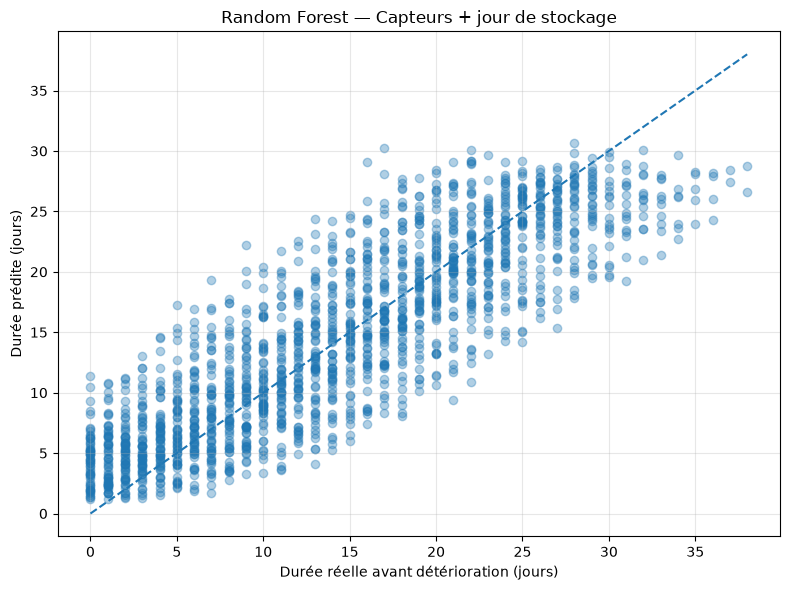

In [24]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, pred_B, alpha=0.35)

# Ligne des prédictions parfaites
min_value = min(y_test.min(), pred_B.min())
max_value = max(y_test.max(), pred_B.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Durée réelle avant détérioration (jours)")
plt.ylabel("Durée prédite (jours)")
plt.title("Random Forest — Capteurs + jour de stockage")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [25]:

evaluation = pd.DataFrame({
    "jours_reels": np.asarray(y_test),
    "jours_predits": pred_B
})

evaluation["erreur"] = (
    evaluation["jours_predits"] - evaluation["jours_reels"]
)

evaluation["tranche"] = pd.cut(
    evaluation["jours_reels"],
    bins=[-1, 5, 10, 20, 30, np.inf],
    labels=["0–5 jours", "6–10 jours", "11–20 jours",
            "21–30 jours", "Plus de 30 jours"]
)

biais_par_tranche = evaluation.groupby(
    "tranche", observed=True
).agg(
    nombre=("erreur", "size"),
    erreur_moyenne=("erreur", "mean"),
    MAE=("erreur", lambda x: x.abs().mean())
).round(3)

display(biais_par_tranche)


,nombre,erreur_moyenne,MAE
tranche,,,
0–5 jours,360,3.139,3.417
6–10 jours,300,1.308,3.197
11–20 jours,594,0.131,3.693
21–30 jours,413,-1.929,3.396
Plus de 30 jours,58,-7.246,7.246


In [26]:

# Évaluer les prédictions lorsque la détérioration est proche
near_expiration = evaluation[
    evaluation["jours_reels"] <= 5
].copy()

near_expiration["alerte_tardive"] = (
    near_expiration["erreur"] > 2
)

total = len(near_expiration)
alertes_tardives = near_expiration["alerte_tardive"].sum()

print("Observations avec 5 jours restants ou moins :", total)
print("Surestimations de plus de 2 jours :", alertes_tardives)
print(
    "Taux de surestimation dangereuse : "
    f"{100 * alertes_tardives / total:.2f}%"
)


Observations avec 5 jours restants ou moins : 360
Surestimations de plus de 2 jours : 217
Taux de surestimation dangereuse : 60.28%


Tester une marge de sécurité

In [27]:

# Simulation d'une marge de sécurité de 2 jours
near_expiration["prediction_corrigee"] = (
    near_expiration["jours_predits"] - 2
).clip(lower=0)

near_expiration["erreur_corrigee"] = (
    near_expiration["prediction_corrigee"]
    - near_expiration["jours_reels"]
)

near_expiration["alerte_tardive_corrigee"] = (
    near_expiration["erreur_corrigee"] > 2
)

taux_initial = 100 * (
    near_expiration["erreur"] > 2
).mean()

taux_corrige = 100 * (
    near_expiration["alerte_tardive_corrigee"]
).mean()

print(f"Taux initial : {taux_initial:.2f}%")
print(f"Taux après correction : {taux_corrige:.2f}%")
print(
    "MAE initiale : "
    f"{near_expiration['erreur'].abs().mean():.3f} jours"
)
print(
    "MAE corrigée : "
    f"{near_expiration['erreur_corrigee'].abs().mean():.3f} jours"
)


Taux initial : 60.28%
Taux après correction : 35.28%
MAE initiale : 3.417 jours
MAE corrigée : 2.340 jours


Soustraire 2 jours améliore les deux indicateurs dans ce sous-ensemble. Cependant :
- 35,28 % des observations restent dangereusement surestimées selon notre définition.
- Nous n'avons pas encore évalué les alertes prématurées ni l'effet sur l'ensemble du jeu de test.
- Les observations sont regroupées par lot : une évaluation fiable doit tenir compte de cette dépendance.
- Les données sont synthétiques ; cette marge de sécurité n'est donc pas encore validée pour des bananes réelles.

comparer plusieurs marges

In [28]:

resultats_marges = []

for marge in [0, 1, 2, 3, 4, 5]:
    prediction_corrigee = (
        near_expiration["jours_predits"] - marge
    ).clip(lower=0)

    erreur = (
        prediction_corrigee - near_expiration["jours_reels"]
    )

    resultats_marges.append({
        "Marge (jours)": marge,
        "MAE": erreur.abs().mean(),
        "Surestimation > 2 jours (%)": (
            100 * (erreur > 2).mean()
        ),
        "Sous-estimation > 2 jours (%)": (
            100 * (erreur < -2).mean()
        ),
    })

display(pd.DataFrame(resultats_marges).round(2))


,Marge (jours),MAE,Surestimation > 2 jours (%),Sous-estimation > 2 jours (%)
0,0,3.42,60.28,2.50
1,1,2.75,48.06,5.28
2,2,2.34,35.28,10.56
3,3,2.13,24.17,18.06
4,4,2.06,15.56,25.83
5,5,2.08,9.72,31.94


Très bien ! Ce tableau met en évidence un compromis important pour ton système IoT : plus la marge de sécurité augmente, moins le modèle surestime dangereusement la durée restante, mais plus il risque de sous-estimer cette durée.

Ce que nous apprenons
- Marge de 2 jours : compromis intermédiaire, mais plus d'un tiers des observations restent surestimées de plus de 2 jours.
- Marge de 4 jours : meilleure MAE dans ce test, à 2,06 jours.
- Marge de 5 jours : taux de surestimation dangereuse le plus faible, mais près d'un tiers des observations sont désormais sous-estimées de plus de 2 jours.
Il n'existe donc pas une marge universellement optimale. Le choix dépendra du coût d'une détérioration non anticipée par rapport au coût d'une alerte prématurée.

Évaluation les marges sur toutes les observations

In [29]:

resultats_globaux = []

for marge in range(6):
    # Corriger les prédictions du modèle B
    prediction_corrigee = pd.Series(
        (pred_B - marge).clip(min=0),
        index=y_test.index if hasattr(y_test, "index") else None
    )

    y_reel = np.asarray(y_test)
    y_predit = np.asarray(prediction_corrigee)

    erreurs = y_predit - y_reel

    resultats_globaux.append({
        "Marge (jours)": marge,
        "MAE": np.mean(np.abs(erreurs)),
        "RMSE": np.sqrt(np.mean(erreurs ** 2)),
        "Surestimation > 2 jours (%)": 100 * np.mean(erreurs > 2),
        "Sous-estimation > 2 jours (%)": 100 * np.mean(erreurs < -2),
    })

tableau_marges_globales = pd.DataFrame(resultats_globaux)
display(tableau_marges_globales.round(2))


,Marge (jours),MAE,RMSE,Surestimation > 2 jours (%),Sous-estimation > 2 jours (%)
0,0,3.60,4.54,33.45,29.45
1,1,3.63,4.60,26.20,37.80
2,2,3.85,4.87,19.94,47.36
3,3,4.23,5.30,15.01,55.01
4,4,4.71,5.85,10.84,63.65
5,5,5.26,6.47,6.72,69.62


vérifier la généralisation par lot

In [30]:

# Construire les résultats de test avec les identifiants des lots
evaluation_lots = pd.DataFrame({
    "lot_id": df.loc[X_test_B.index, "lot_id"].to_numpy(),
    "jours_reels": np.asarray(y_test),
    "jours_predits": np.asarray(pred_B),
})

evaluation_lots["erreur_absolue"] = (
    evaluation_lots["jours_predits"]
    - evaluation_lots["jours_reels"]
).abs()

# Chaque lot reçoit le même poids
mae_par_lot = evaluation_lots.groupby("lot_id")[
    "erreur_absolue"
].mean()

print("Nombre de lots de test :", len(mae_par_lot))
print("MAE moyenne par lot :", round(mae_par_lot.mean(), 3))
print("Médiane de la MAE par lot :", round(mae_par_lot.median(), 3))
print("90e percentile de la MAE par lot :", round(mae_par_lot.quantile(0.90), 3))


Nombre de lots de test : 60
MAE moyenne par lot : 3.721
Médiane de la MAE par lot : 2.978
90e percentile de la MAE par lot : 6.971


Nous avons maintenant une évaluation complémentaire qui donne le même poids à chacun des 60 lots de test, au lieu de considérer toutes les observations quotidiennes comme indépendantes.
1. Résultats par lot
MAE moyenne par lot
3,721 jours

MAE médiane
2,978 jours

90e percentile
6,971 jours

Lots évalués
60



Voici comment les interpréter :
- MAE moyenne de 3,721 jours : en moyenne, l'erreur absolue quotidienne calculée au sein de chaque lot est d'environ 3,7 jours, puis moyennée entre les lots.
- Médiane de 2,978 jours : la moitié des lots ont une MAE inférieure ou égale à environ 3 jours.
- 90e percentile de 6,971 jours : environ 90 % des lots ont une MAE inférieure ou égale à 7 jours, et les lots les plus difficiles présentent des erreurs plus élevées.
Ces résultats suggèrent que la précision varie sensiblement d'un lot à l'autre.

identifions les lots les plus difficiles

In [31]:

resume_par_lot = (
    evaluation_lots.groupby("lot_id")
    .agg(
        MAE=("erreur_absolue", "mean"),
        duree_reelle_moyenne=("jours_reels", "mean"),
        observations=("jours_reels", "size"),
    )
    .sort_values("MAE", ascending=False)
)

display(resume_par_lot.head(10).round(3))


,MAE,duree_reelle_moyenne,observations
lot_id,,,
LOT-0091,10.745,8.5,18
LOT-0026,9.751,9.0,19
LOT-0279,9.196,9.5,20
LOT-0074,7.604,19.0,39
LOT-0296,7.283,19.0,39
LOT-0212,7.041,10.5,22
LOT-0282,6.963,10.0,21
LOT-0120,6.646,11.0,23
LOT-0239,6.517,10.5,22


Ces résultats sont intéressants : les erreurs les plus importantes se concentrent notamment sur des lots dont la durée de conservation totale semble courte. Par exemple, LOT-0091 présente une MAE de 10,745 jours, contre environ 3,7 jours en moyenne par lot.

Examinons un lot difficile

In [32]:

lot_a_analyser = "LOT-0091"

details_lot = evaluation_lots[
    evaluation_lots["lot_id"] == lot_a_analyser
].copy()

# Ajouter les jours de stockage et les capteurs correspondants
details_lot["storage_day"] = df.loc[
    X_test_B.index, "storage_day"
].to_numpy()[
    evaluation_lots["lot_id"].to_numpy() == lot_a_analyser
]

details_lot = details_lot.sort_values("storage_day")

display(details_lot.round(2))


,lot_id,jours_reels,jours_predits,erreur_absolue,storage_day
539,LOT-0091,17,30.21,13.21,0
540,LOT-0091,16,29.05,13.05,1
541,LOT-0091,15,24.46,9.46,2
542,LOT-0091,14,22.93,8.93,3
543,LOT-0091,13,24.36,11.36,4
544,LOT-0091,12,22.53,10.53,5
545,LOT-0091,11,19.88,8.88,6
546,LOT-0091,10,19.87,9.87,7
547,LOT-0091,9,22.24,13.24,8
548,LOT-0091,8,17.42,9.42,9


Trois observations importantes :
- Biais systématique : le modèle ne se contente pas de faire quelques erreurs ponctuelles ; il surestime constamment ce lot.
- Détérioration non détectée : à la fin du cycle, il annonce encore plus de 11 jours restants.
- Limite structurelle possible : le modèle a vraisemblablement appris une relation générale qui ne représente pas correctement ce lot.
Cela ne prouve pas que le Random Forest est intrinsèquement mauvais. Le générateur synthétique peut produire des lots dont les caractéristiques sont insuffisamment liées à leur durée de conservation réelle.

examiner les capteurs de ce lot

In [33]:

# Comparer les mesures du lot difficile à celles des autres lots de test
indices_test = X_test_B.index

donnees_test = df.loc[indices_test].copy()
donnees_test["jours_reels"] = np.asarray(y_test)
donnees_test["jours_predits"] = np.asarray(pred_B)

lot_cible = donnees_test[
    donnees_test["lot_id"] == "LOT-0091"
]

autres_lots = donnees_test[
    donnees_test["lot_id"] != "LOT-0091"
]

colonnes_capteurs = [
    "temperature",
    "humidity",
    "mq2_raw",
    "fc28_raw",
    "ldr_raw",
]

comparaison_capteurs = pd.DataFrame({
    "LOT-0091": lot_cible[colonnes_capteurs].mean(),
    "Autres lots — moyenne": autres_lots[colonnes_capteurs].mean(),
})

display(comparaison_capteurs.round(2))


,LOT-0091,Autres lots — moyenne
temperature,13.32,13.53
humidity,93.39,89.87
mq2_raw,1057.83,1183.73
fc28_raw,2871.78,2695.60
ldr_raw,2565.61,2115.94


Le point qui attire l'attention est l'humidité plus élevée du LOT-0091. Une humidité élevée peut favoriser certains problèmes de conservation selon les conditions de stockage. Cependant, les valeurs du MQ-2 et du FC-28 ne permettent pas, à elles seules, de conclure que les bananes sont en meilleur ou en moins bon état.
Surtout, ces différences ne prouvent pas pourquoi le modèle s'est trompé : notre dataset est synthétique et la date d'expiration y a été générée indépendamment des capteurs.

Vérifions maintenant les prédictions de ce lot

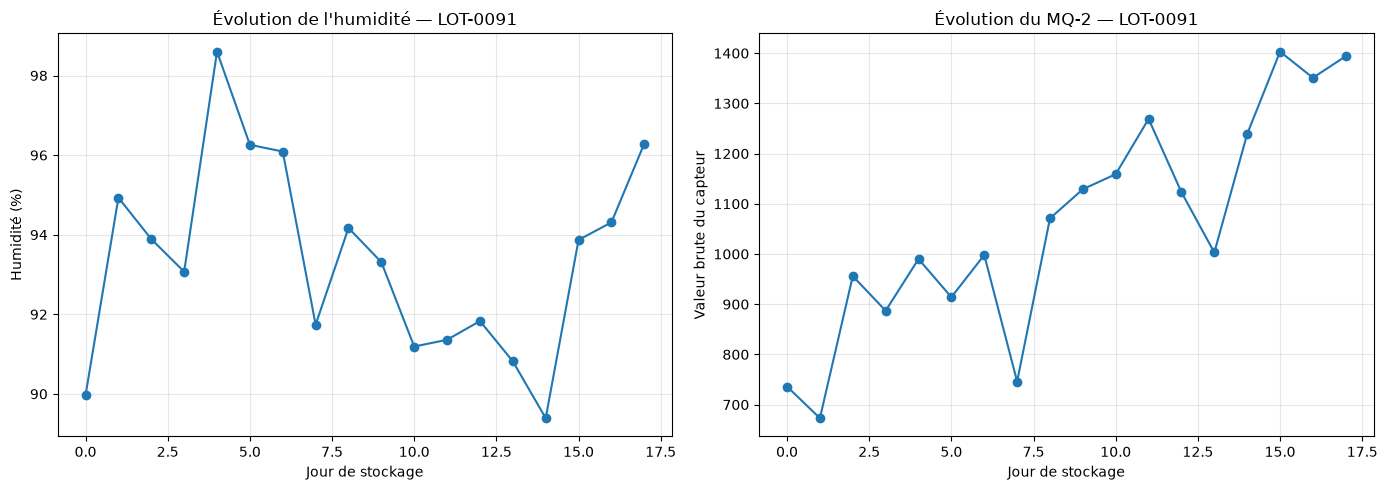

,storage_day,humidity,mq2_raw,fc28_raw,days_until_bad
2584,0,89.97,736,3139,17
2585,1,94.93,673,2998,16
2586,2,93.89,956,3119,15
2587,3,93.07,887,3219,14
2588,4,98.60,990,3210,13
2589,5,96.26,914,2921,12
2590,6,96.09,998,3022,11
2591,7,91.74,746,2700,10
2592,8,94.17,1071,2896,9
2593,9,93.31,1129,2904,8


In [34]:

# Évolution des capteurs du LOT-0091 au cours du stockage

lot_0091 = df[df["lot_id"] == "LOT-0091"].sort_values("storage_day")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    lot_0091["storage_day"],
    lot_0091["humidity"],
    marker="o"
)
axes[0].set_title("Évolution de l'humidité — LOT-0091")
axes[0].set_xlabel("Jour de stockage")
axes[0].set_ylabel("Humidité (%)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    lot_0091["storage_day"],
    lot_0091["mq2_raw"],
    marker="o",
    label="MQ-2"
)
axes[1].set_title("Évolution du MQ-2 — LOT-0091")
axes[1].set_xlabel("Jour de stockage")
axes[1].set_ylabel("Valeur brute du capteur")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

display(
    lot_0091[
        ["storage_day", "humidity", "mq2_raw",
         "fc28_raw", "days_until_bad"]
    ].round(2)
)


In [35]:

from pathlib import Path
import json

notebook_path = Path("notebooks/03_shelf_life_analysis.ipynb")

if not notebook_path.exists():
    notebook_path = Path("../notebooks/03_shelf_life_analysis.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    if any(
        mot in source.lower()
        for mot in [
            "expiration_day",
            "days_until_bad",
            "np.random.normal",
            "banana_shelf_life_synthetic"
        ]
    ):
        print(f"\n{'=' * 20} CELLULE {i} {'=' * 20}")
        print(source[:5000])



==================== CELLULE 1 ====================


PROJECT_ROOT = Path.cwd()

# Permet aussi de fonctionner si le notebook est lancé depuis notebooks/
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "banana_shelf_life_synthetic.csv"
)

df = pd.read_csv(DATA_PATH)

print(f"Dataset chargé : {DATA_PATH}")
print(f"Dimensions : {df.shape[0]} lignes × {df.shape[1]} colonnes")

display(df.head())


==================== CELLULE 8 ====================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="days_until_bad",
    bins=25,
    kde=True,
    ax=axes[0],
)
axes[0].set_title("Distribution des jours avant le seuil MAUVAIS")
axes[0].set_xlabel("Jours restants")
axes[0].set_ylabel("Nombre d'observations")

sns.countplot(
    data=df,
    x="quality",
    order=["acceptable", "mauvais"],
    ax=axes[1],
)
axes[1].set_title("Répartition des états de qualité")

In [36]:

from pathlib import Path

project_root = Path.cwd()

if not (project_root / "data").exists():
    project_root = project_root.parent

keywords = [
    "expiration_day",
    "days_until_bad",
    "banana_shelf_life_synthetic",
]

extensions = {".py", ".ipynb"}

for path in project_root.rglob("*"):
    if (
        not path.is_file()
        or path.suffix not in extensions
        or any(part in {".venv", ".git", "__pycache__"}
               for part in path.parts)
    ):
        continue

    try:
        content = path.read_text(encoding="utf-8")
    except (UnicodeDecodeError, OSError):
        continue

    matches = [word for word in keywords if word in content]

    if matches:
        print(f"\nFichier : {path.relative_to(project_root)}")
        print(f"Mots-clés : {', '.join(matches)}")

        lines = content.splitlines()
        for i, line in enumerate(lines):
            if any(word in line for word in keywords):
                start = max(0, i - 5)
                end = min(len(lines), i + 8)
                print("\n".join(
                    f"{j + 1}: {lines[j]}"
                    for j in range(start, end)
                ))
                print("-" * 50)



Fichier : notebooks\03_shelf_life_analysis.ipynb
Mots-clés : expiration_day, days_until_bad, banana_shelf_life_synthetic
32:    "outputs": [
33:     {
34:      "name": "stdout",
35:      "output_type": "stream",
36:      "text": [
37:       "Dataset chargé : c:\\Users\\babacar\\model_ml_iot\\data\\processed\\banana_shelf_life_synthetic.csv\n",
38:       "Dimensions : 8641 lignes × 12 colonnes\n"
39:      ]
40:     },
41:     {
42:      "data": {
43:       "text/html": [
44:        "<div>\n",
--------------------------------------------------
67:        "      <th>fc28_raw</th>\n",
68:        "      <th>liquid_detected</th>\n",
69:        "      <th>motion_detected</th>\n",
70:        "      <th>ldr_raw</th>\n",
71:        "      <th>quality</th>\n",
72:        "      <th>days_until_bad</th>\n",
73:        "      <th>is_expired</th>\n",
74:        "    </tr>\n",
75:        "  </thead>\n",
76:        "  <tbody>\n",
77:        "    <tr>\n",
78:        "      <th>0</th>\n",
79:        "  

In [37]:

from pathlib import Path
import json

notebook_path = Path("notebooks/03_shelf_life_analysis.ipynb")

if not notebook_path.exists():
    notebook_path = Path("../notebooks/03_shelf_life_analysis.ipynb")

nb = json.loads(notebook_path.read_text(encoding="utf-8"))

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if cell["cell_type"] == "code":
        for output in cell.get("outputs", []):
            text_output = "".join(output.get("text", []))
            if any(k in text_output.lower() for k in [
                "expiration_day",
                "generating",
                "génération",
                "synthetic dataset",
                "dataset synthétique"
            ]):
                print(f"\n--- Cellule {i} : sortie ---")
                print(text_output[:3000])

        if any(k in source.lower() for k in [
            "expiration_day =",
            "for lot_id in",
            "days_until_bad =",
            "np.clip"
        ]):
            print(f"\n--- Cellule {i} : code ---")
            print(source[:4000])



--- Cellule 58 : sortie ---

==================== CELLULE 1 ====================


PROJECT_ROOT = Path.cwd()

# Permet aussi de fonctionner si le notebook est lancé depuis notebooks/
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "banana_shelf_life_synthetic.csv"
)

df = pd.read_csv(DATA_PATH)

print(f"Dataset chargé : {DATA_PATH}")
print(f"Dimensions : {df.shape[0]} lignes × {df.shape[1]} colonnes")

display(df.head())


==================== CELLULE 8 ====================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="days_until_bad",
    bins=25,
    kde=True,
    ax=axes[0],
)
axes[0].set_title("Distribution des jours avant le seuil MAUVAIS")
axes[0].set_xlabel("Jours restants")
axes[0].set_ylabel("Nombre d'observations")

sns.countplot(
    data=df,
    x="quality",
    order=["acceptable", "mauvais"],
    ax=axes[1],
)
axes[1].set_title("Répar